# In this notebook we will run our final model for Fuel Modes (Hybrid, Mono-Fuel, PHEV) separately to investigate the model performance.

# 1. Import and Inspect the Data

Load the cleaned 2024 and 2025 FR datasets. The 2024 dataset is used for model development, while the 2025 dataset is kept separate for the final test evaluation.

In [47]:
import pandas as pd
import numpy as np
import joblib
import json
from pathlib import Path

pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)


df_2024_FR_cleaned_final = pd.read_csv("../data/processed/eu/splits/final/no_dupes/2024_FR_cleaned_final.csv")
df_2025_FR_cleaned_final = pd.read_csv("../data/processed/eu/splits/final/no_dupes/2025_FR_cleaned_final.csv")

print("2024 FR Cleaned Final:", df_2024_FR_cleaned_final.shape)
print("2025 FR Cleaned Final:", df_2025_FR_cleaned_final.shape)

2024 FR Cleaned Final: (15957, 20)
2025 FR Cleaned Final: (14735, 20)


# 2. Separate the Data per Fuel Mode:

In [48]:
print("-----")
print("2024:", df_2024_FR_cleaned_final["Fm"].unique())
print("-----")
print("2025:", df_2025_FR_cleaned_final["Fm"].unique())
print("-----")

# 2024
df_2024_Mono = df_2024_FR_cleaned_final[df_2024_FR_cleaned_final["Fm"] == "M"]
df_2024_Phev = df_2024_FR_cleaned_final[df_2024_FR_cleaned_final["Fm"] == "P"]
df_2024_Hybrid = df_2024_FR_cleaned_final[df_2024_FR_cleaned_final["Fm"] == "H"]

# 2024 stats
print("2024 Mono:", df_2024_Mono.shape)
print("2024 Phev:", df_2024_Phev.shape)
print("2024 Hybrid:", df_2024_Hybrid.shape)
print("-----")

# 2025
df_2025_Mono = df_2025_FR_cleaned_final[df_2025_FR_cleaned_final["Fm"] == "M"]
df_2025_Phev = df_2025_FR_cleaned_final[df_2025_FR_cleaned_final["Fm"] == "P"]
df_2025_Hybrid = df_2025_FR_cleaned_final[df_2025_FR_cleaned_final["Fm"] == "H"]

# 2025 stats
print("2025 Mono:", df_2025_Mono.shape)
print("2025 Phev:", df_2025_Phev.shape)
print("2025 Hybrid:", df_2025_Hybrid.shape)
print("-----")

-----
2024: <ArrowStringArray>
['H', 'M', 'P']
Length: 3, dtype: str
-----
2025: <ArrowStringArray>
['H', 'M', 'P']
Length: 3, dtype: str
-----
2024 Mono: (8444, 20)
2024 Phev: (2817, 20)
2024 Hybrid: (4696, 20)
-----
2025 Mono: (6857, 20)
2025 Phev: (2695, 20)
2025 Hybrid: (5183, 20)
-----


# 3. Prepare Splits

In [49]:
def split_train_val_by_group(df, target, group_list, test_size=0.2, random_state=42, n_splits=1):
    # We split the 2024 FR dataset into training and validation sets based on group columns.
    from sklearn.model_selection import GroupShuffleSplit


    group_columns = [
        col for col in group_list
        if col in df.columns
    ]

    group_id_2024 = (
        df
        .groupby(group_columns, dropna=False)
        .ngroup()
    )

    # Divide Target and Features
    TARGET = target
    y_2024 = df[TARGET].copy()

    X_2024 = df.drop(
        columns=[TARGET],
        errors="ignore"
    ).copy()

    # Split
    gss = GroupShuffleSplit(
        n_splits=n_splits,
        test_size=test_size,
        random_state=random_state,
    )

    train_idx, val_idx = next(
        gss.split(
            X_2024,
            y_2024,
            groups=group_id_2024,
        )
    )

    X_train = X_2024.iloc[train_idx].copy()
    X_val = X_2024.iloc[val_idx].copy()

    y_train = y_2024.iloc[train_idx].copy()
    y_val = y_2024.iloc[val_idx].copy()

    print("Train:", X_train.shape)
    print("Validation:", X_val.shape)

    # Control
    train_groups = set(group_id_2024.iloc[train_idx])
    val_groups = set(group_id_2024.iloc[val_idx])

    assert train_groups.isdisjoint(val_groups)

    return X_train, X_val, y_train, y_val


core_physical = [
    "m (kg)",
    "ec (cm3)",
    "ep (KW)",
    "Ft",
    "Fm"
    ]

print("-----")
print("Splitting df_2024_Mono")
X_train_2024_Mono, X_val_2024_Mono, y_train_2024_Mono, y_val_2024_Mono = split_train_val_by_group(
    df=df_2024_Mono,
    target="Ewltp (g/km)",
    group_list=core_physical,
    test_size=0.2,
    random_state=42
)
print("Finished splitting df_2024_Mono")
print("-----")

print("Splitting df_2024_Phev")
X_train_2024_Phev, X_val_2024_Phev, y_train_2024_Phev, y_val_2024_Phev = split_train_val_by_group(
    df=df_2024_Phev,
    target="Ewltp (g/km)",
    group_list=core_physical,
    test_size=0.2,
    random_state=42
)
print("Finished splitting df_2024_Phev")
print("-----")

print("Splitting df_2024_Hybrid")
X_train_2024_Hybrid, X_val_2024_Hybrid, y_train_2024_Hybrid, y_val_2024_Hybrid = split_train_val_by_group(
    df=df_2024_Hybrid,
    target="Ewltp (g/km)",
    group_list=core_physical,
    test_size=0.2,
    random_state=42
)
print("Finished splitting df_2024_Hybrid")
print("-----")

-----
Splitting df_2024_Mono
Train: (6816, 19)
Validation: (1628, 19)
Finished splitting df_2024_Mono
-----
Splitting df_2024_Phev
Train: (2246, 19)
Validation: (571, 19)
Finished splitting df_2024_Phev
-----
Splitting df_2024_Hybrid
Train: (3745, 19)
Validation: (951, 19)
Finished splitting df_2024_Hybrid
-----


# 4. Prepare the Final Test Sets

In [50]:
def prepare_test_set(df, target):
    # Divide target and features for the 2025 FR cleaned final dataset
    y_test = df[target].copy()

    X_test = df.drop(
        columns=[target],
        errors="ignore"
    ).copy()

    # Control
    print(target in df.columns)
    print(df[target].isna().sum())
    return X_test, y_test

print("-----")
print("Preparing 2025 Mono test set")
X_test_2025_Mono, y_test_2025_Mono = prepare_test_set(
    df=df_2025_Mono,
    target="Ewltp (g/km)"
)

print("-----")
print("Preparing 2025 Phev test set")
X_test_2025_Phev, y_test_2025_Phev = prepare_test_set(
    df=df_2025_Phev,
    target="Ewltp (g/km)"
)

print("-----")
print("Preparing 2025 Hybrid test set")
X_test_2025_Hybrid, y_test_2025_Hybrid = prepare_test_set(
    df=df_2025_Hybrid,
    target="Ewltp (g/km)"
)
print("-----")

-----
Preparing 2025 Mono test set
True
0
-----
Preparing 2025 Phev test set
True
0
-----
Preparing 2025 Hybrid test set
True
0
-----


In [51]:
# Since we divided the data by vehicle type, we can drop the "Fm" column from each subset
X_train_2024_Mono.drop("Fm", axis=1, inplace=True, errors='ignore')
X_train_2024_Phev.drop("Fm", axis=1, inplace=True, errors='ignore')
X_train_2024_Hybrid.drop("Fm", axis=1, inplace=True, errors='ignore')

X_val_2024_Mono.drop("Fm", axis=1, inplace=True, errors='ignore')
X_val_2024_Phev.drop("Fm", axis=1, inplace=True, errors='ignore')
X_val_2024_Hybrid.drop("Fm", axis=1, inplace=True, errors='ignore')

X_test_2025_Mono.drop("Fm", axis=1, inplace=True, errors='ignore')
X_test_2025_Phev.drop("Fm", axis=1, inplace=True, errors='ignore')
X_test_2025_Hybrid.drop("Fm", axis=1, inplace=True, errors='ignore')

# 6. Apply Target encoding for Mk

In [52]:
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import TargetEncoder
from sklearn import set_config

set_config(enable_metadata_routing=True)

def apply_target_encoding_for_make(X_train, X_val, X_test, y_train):

    core_physical = [
        "m (kg)",
        "ec (cm3)",
        "ep (KW)",
        "Ft",
        "Fm"
    ]

    group_columns = [
        col for col in core_physical
        if col in X_train.columns
    ]

    # Create groups based solely on the training data
    train_group_ids = (
        X_train
        .groupby(group_columns, dropna=False)
        .ngroup()
        .to_numpy()
    )

    target_encoder_cv = GroupKFold(n_splits=5)

    make_target_encoder = TargetEncoder(
        smooth="auto",
        target_type="continuous",
        cv=target_encoder_cv
    )

    # Target encoding based on the "Mk" column
    X_train_make_encoded = make_target_encoder.fit_transform(
        X_train[["Mk"]],
        y_train,
        groups=train_group_ids
    )

    X_train = X_train.copy()
    X_val = X_val.copy()
    X_test = X_test.copy()

    X_train["Make_Encoded"] = X_train_make_encoded[:, 0]

    # Validation: transform only
    X_val_make_encoded = make_target_encoder.transform(
        X_val[["Mk"]]
    )

    X_val["Make_Encoded"] = X_val_make_encoded[:, 0]

    # 2025 test: transform only
    X_test_make_encoded = make_target_encoder.transform(
        X_test[["Mk"]]
    )

    X_test["Make_Encoded"] = X_test_make_encoded[:, 0]

    # Drop the original "Mk" column
    X_train = X_train.drop(
        columns=["Mk"],
        errors="ignore"
    )

    X_val = X_val.drop(
        columns=["Mk"],
        errors="ignore"
    )

    X_test = X_test.drop(
        columns=["Mk"],
        errors="ignore"
    )

    return X_train, X_val, X_test

print("-----")
print("Applying target encoding for Make_Grouped in Mono datasets")
X_train_2024_Mono, X_val_2024_Mono, X_test_2025_Mono = apply_target_encoding_for_make(
    X_train_2024_Mono,
    X_val_2024_Mono,
    X_test_2025_Mono,
    y_train_2024_Mono
)
print("-----")

print("Applying target encoding for Make_Grouped in Phev datasets")
X_train_2024_Phev, X_val_2024_Phev, X_test_2025_Phev = apply_target_encoding_for_make(
    X_train_2024_Phev,
    X_val_2024_Phev,
    X_test_2025_Phev,
    y_train_2024_Phev
)
print("-----")

print("Applying target encoding for Make_Grouped in Hybrid datasets")
X_train_2024_Hybrid, X_val_2024_Hybrid, X_test_2025_Hybrid = apply_target_encoding_for_make(
    X_train_2024_Hybrid,
    X_val_2024_Hybrid,
    X_test_2025_Hybrid,
    y_train_2024_Hybrid
)
print("-----")

-----
Applying target encoding for Make_Grouped in Mono datasets
-----
Applying target encoding for Make_Grouped in Phev datasets
-----
Applying target encoding for Make_Grouped in Hybrid datasets
-----


# 7. Perform frequency encoding based on the training data

In [53]:
def add_frequency_feature(
    train_frame,
    other_frames,
    source_column,
    output_column,
):
    frequency_map = (
        train_frame[source_column]
        .value_counts(dropna=False)
    )

    train_frame[output_column] = (
        train_frame[source_column]
        .map(frequency_map)
        .fillna(0)
        .astype("int32")
    )

    for frame in other_frames:
        frame[output_column] = (
            frame[source_column]
            .map(frequency_map)
            .fillna(0)
            .astype("int32")
        )

    return train_frame, other_frames

frequency_columns = {
    "Cn": "Model_Frequency",
    "VFN": "VFN_Frequency",
    "Tan": "Tan_Frequency",
    "Va": "Va_Frequency",
    "Ve": "Ve_Frequency",
    "RLFI": "RLFI_Frequency",
}

def add_frequency_features_for_columns(X_train, X_val, X_test, frequency_columns):
    for source_column, output_column in frequency_columns.items():
        if source_column not in X_train.columns:
            continue

        X_train, [X_val, X_test] = add_frequency_feature(
            train_frame=X_train,
            other_frames=[X_val, X_test],
            source_column=source_column,
            output_column=output_column,
        )

    # Drop the original categorical columns after adding frequency features
    for column in frequency_columns.keys():
        if column in X_train.columns:
            X_train.drop(columns=column, inplace=True)
            X_val.drop(columns=column, inplace=True)
            X_test.drop(columns=column, inplace=True)
    return X_train, X_val, X_test
    # Important: In 2025, a category that was never seen in the training data will have a frequency of 0. This is expected behavior.

print("-----")
print("Applying frequency features to Mono datasets")
X_train_2024_Mono, X_val_2024_Mono, X_test_2025_Mono = add_frequency_features_for_columns(
    X_train_2024_Mono,
    X_val_2024_Mono,
    X_test_2025_Mono,
    frequency_columns
)
print("-----")

print("Applying frequency features to Phev datasets")
X_train_2024_Phev, X_val_2024_Phev, X_test_2025_Phev = add_frequency_features_for_columns(
    X_train_2024_Phev,
    X_val_2024_Phev,
    X_test_2025_Phev,
    frequency_columns
)
print("-----")

print("Applying frequency features to Hybrid datasets")
X_train_2024_Hybrid, X_val_2024_Hybrid, X_test_2025_Hybrid = add_frequency_features_for_columns(
    X_train_2024_Hybrid,
    X_val_2024_Hybrid,
    X_test_2025_Hybrid,
    frequency_columns
)
print("-----")


-----
Applying frequency features to Mono datasets
-----
Applying frequency features to Phev datasets
-----
Applying frequency features to Hybrid datasets
-----


# 8. Implement IT encoding in a shared and leakage-free manner

In [54]:
# Since no target information is used for IT, the same function can be applied to all sets
import re

IT_CODES = ["28", "29", "32", "33", "37", "38", "none"]


def extract_it_tokens(value):
    return re.findall(
        r"\b\d+\b|\bnone\b",
        str(value).lower(),
    )


def encode_it_columns(frame, it_column="IT"):
    frame = frame.copy()

    it_tokens = frame[it_column].map(
        extract_it_tokens
    )

    for code in IT_CODES:
        frame[f"IT_{code}"] = (
            it_tokens
            .map(lambda tokens: int(code in tokens))
            .astype("int8")
        )

    return frame.drop(
        columns=[it_column],
        errors="ignore"
    )

X_train_2024_Mono = encode_it_columns(X_train_2024_Mono)
X_val_2024_Mono = encode_it_columns(X_val_2024_Mono)
X_test_2025_Mono = encode_it_columns(X_test_2025_Mono)

X_train_2024_Phev = encode_it_columns(X_train_2024_Phev)
X_val_2024_Phev = encode_it_columns(X_val_2024_Phev)
X_test_2025_Phev = encode_it_columns(X_test_2025_Phev)

X_train_2024_Hybrid = encode_it_columns(X_train_2024_Hybrid)
X_val_2024_Hybrid = encode_it_columns(X_val_2024_Hybrid)
X_test_2025_Hybrid = encode_it_columns(X_test_2025_Hybrid)

# 9. Ft One-Hot Encoding

In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
import pandas as pd
import re

onehot_columns = ["Ft"]

def apply_ohe_to_columns(X_train, X_val, X_test, onehot_columns):
    fuel_onehot_pipeline = Pipeline(
        steps=[
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("fuel_onehot", fuel_onehot_pipeline, onehot_columns),
        ],
        remainder="passthrough",
        sparse_threshold=0,
    )

    # Fit and transform
    X_train_encoded_array = preprocessor.fit_transform(X_train)
    X_val_encoded_array   = preprocessor.transform(X_val)
    X_test_encoded_array  = preprocessor.transform(X_test)

    # Get all column names and remove prefixes
    raw_columns = preprocessor.get_feature_names_out()

    def clean_column_name(name: str) -> str:
        """Remove 'fuel_onehot__' and 'remainder__' prefixes"""
        return re.sub(r"^(fuel_onehot|remainder)__", "", name)

    all_columns = [clean_column_name(col) for col in raw_columns]

    # Convert to DataFrame
    X_train_encoded = pd.DataFrame(
        X_train_encoded_array,
        columns=all_columns,
        index=X_train.index,
    )

    X_val_encoded = pd.DataFrame(
        X_val_encoded_array,
        columns=all_columns,
        index=X_val.index,
    )

    X_test_encoded = pd.DataFrame(
        X_test_encoded_array,
        columns=all_columns,
        index=X_test.index,
    )
    return X_train_encoded, X_val_encoded, X_test_encoded

print("-----")
print("Applying one-hot encoding to Ft columns on Mono datasets")
X_train_2024_Mono, X_val_2024_Mono, X_test_2025_Mono = apply_ohe_to_columns(
    X_train_2024_Mono,
    X_val_2024_Mono,
    X_test_2025_Mono,
    onehot_columns
)
print("-----")

print("Applying one-hot encoding to Ft columns on Phev datasets")
X_train_2024_Phev, X_val_2024_Phev, X_test_2025_Phev = apply_ohe_to_columns(
    X_train_2024_Phev,
    X_val_2024_Phev,
    X_test_2025_Phev,
    onehot_columns
)
print("-----")

print("Applying one-hot encoding to Ft columns on Hybrid datasets")
X_train_2024_Hybrid, X_val_2024_Hybrid, X_test_2025_Hybrid = apply_ohe_to_columns(
    X_train_2024_Hybrid,
    X_val_2024_Hybrid,
    X_test_2025_Hybrid,
    onehot_columns
)
print("-----")

-----
Applying one-hot encoding to Ft columns on Mono datasets
-----
Applying one-hot encoding to Ft columns on Phev datasets
-----
Applying one-hot encoding to Ft columns on Hybrid datasets
-----


In [56]:
print("Columns in Mono datasets")
print(X_train_2024_Mono.columns.to_list())
print(X_val_2024_Mono.columns.to_list())
print(X_test_2025_Mono.columns.to_list())

print("\nColumns in Phev datasets")
print(X_train_2024_Phev.columns.to_list())
print(X_val_2024_Phev.columns.to_list())
print(X_test_2025_Phev.columns.to_list())

print("\nColumns in Hybrid datasets")
print(X_train_2024_Hybrid.columns.to_list())
print(X_val_2024_Hybrid.columns.to_list())
print(X_test_2025_Hybrid.columns.to_list())

Columns in Mono datasets
['Ft_diesel', 'Ft_petrol', 'ec (cm3)', 'ep (KW)', 'T', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'r', 'Make_Encoded', 'Model_Frequency', 'VFN_Frequency', 'Tan_Frequency', 'Va_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
['Ft_diesel', 'Ft_petrol', 'ec (cm3)', 'ep (KW)', 'T', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'r', 'Make_Encoded', 'Model_Frequency', 'VFN_Frequency', 'Tan_Frequency', 'Va_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
['Ft_diesel', 'Ft_petrol', 'ec (cm3)', 'ep (KW)', 'T', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'r', 'Make_Encoded', 'Model_Frequency', 'VFN_Frequency', 'Tan_Frequency', 'Va_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']

Columns in Phev datasets
[

# 10. Group-Aware Split Validation:

In [57]:
# unseen configuration identifiers
configuration_features = [
    "m (kg)", "ec (cm3)", "ep (KW)", 'Ft_diesel', 'Ft_petrol', 'Ft_petrol/electric', "Ft_diesel/electric"]

def validate_configuration_overlap(X_train_encoded, X_val_encoded, X_test_encoded, configuration_features):

    configuration_features = [
        col for col in configuration_features
        if col in X_train_encoded.columns
    ]

    def make_configuration_id(frame, columns):
        return (
            frame[columns]
            .astype(str)
            .fillna("<NA>")
            .agg("|".join, axis=1)
        )

    train_config_id = make_configuration_id(
        X_train_encoded,
        configuration_features,
    )

    val_config_id = make_configuration_id(
        X_val_encoded,
        configuration_features,
    )

    test_config_id = make_configuration_id(
        X_test_encoded,
        configuration_features,
    )

    train_configuration_set = set(train_config_id)

    val_overlap = val_config_id.isin(train_configuration_set)
    test_overlap = test_config_id.isin(train_configuration_set)

    print(
        "Validation rows with an exact train configuration:",
        f"{val_overlap.sum():,} / {len(val_overlap):,}",
        f"({val_overlap.mean() * 100:.2f}%)",
    )

    print(
        "2025 rows with an exact train configuration:",
        f"{test_overlap.sum():,} / {len(test_overlap):,}",
        f"({test_overlap.mean() * 100:.2f}%)",
    )

    print(
        "\nUnique train configurations:",
        f"{train_config_id.nunique():,}",
    )

    print(
        "Unique validation configurations:",
        f"{val_config_id.nunique():,}",
    )

    print(
        "Unique 2025 configurations:",
        f"{test_config_id.nunique():,}",
    )
    return train_config_id, val_config_id, test_config_id

print("-----")
print("Validating configuration overlap for Mono datasets")
train_config_id_mono, val_config_id_mono, test_config_id_mono = validate_configuration_overlap(X_train_2024_Mono, X_val_2024_Mono, X_test_2025_Mono, configuration_features)
print("-----")

print("\nValidating configuration overlap for Phev datasets")
train_config_id_phev, val_config_id_phev, test_config_id_phev = validate_configuration_overlap(X_train_2024_Phev, X_val_2024_Phev, X_test_2025_Phev, configuration_features)
print("-----")

print("\nValidating configuration overlap for Hybrid datasets")
train_config_id_hybrid, val_config_id_hybrid, test_config_id_hybrid = validate_configuration_overlap(X_train_2024_Hybrid, X_val_2024_Hybrid, X_test_2025_Hybrid, configuration_features)
print("-----")

-----
Validating configuration overlap for Mono datasets
Validation rows with an exact train configuration: 0 / 1,628 (0.00%)
2025 rows with an exact train configuration: 4,799 / 6,857 (69.99%)

Unique train configurations: 1,208
Unique validation configurations: 303
Unique 2025 configurations: 1,216
-----

Validating configuration overlap for Phev datasets
Validation rows with an exact train configuration: 0 / 571 (0.00%)
2025 rows with an exact train configuration: 1,821 / 2,695 (67.57%)

Unique train configurations: 360
Unique validation configurations: 91
Unique 2025 configurations: 455
-----

Validating configuration overlap for Hybrid datasets
Validation rows with an exact train configuration: 0 / 951 (0.00%)
2025 rows with an exact train configuration: 3,370 / 5,183 (65.02%)

Unique train configurations: 729
Unique validation configurations: 183
Unique 2025 configurations: 871
-----


# 11. Scaling

In [58]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler


split_dir = Path("../data/processed/eu/splits/final")
split_dir.mkdir(parents=True, exist_ok=True)


numeric_cols = [
    "ec (cm3)",
    "ep (KW)",
    "m (kg)",
    "Mt",
    "z (Wh/km)",
    "Electric range (km)",
    "Fuel consumption",
    "Model_Frequency",
    "Make_Encoded",
    "VFN_Frequency",
    "Tan_Frequency",
    "Va_Frequency",
    "Ve_Frequency",
    "RLFI_Frequency",
]


def scale_numeric_columns(
    X_train_encoded,
    X_val_encoded,
    X_test_encoded,
    numeric_cols,
):
    existing_numeric_cols = [
        col
        for col in numeric_cols
        if col in X_train_encoded.columns
    ]

    scaler = ColumnTransformer(
        transformers=[
            ("scaler", StandardScaler(), existing_numeric_cols),
        ],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )

    X_train_scaled_array = scaler.fit_transform(X_train_encoded)
    X_val_scaled_array = scaler.transform(X_val_encoded)
    X_test_scaled_array = scaler.transform(X_test_encoded)

    remainder_cols = [
        col
        for col in X_train_encoded.columns
        if col not in existing_numeric_cols
    ]

    output_columns = existing_numeric_cols + remainder_cols

    X_train_scaled = pd.DataFrame(
        X_train_scaled_array,
        columns=output_columns,
        index=X_train_encoded.index,
    )

    X_val_scaled = pd.DataFrame(
        X_val_scaled_array,
        columns=output_columns,
        index=X_val_encoded.index,
    )

    X_test_scaled = pd.DataFrame(
        X_test_scaled_array,
        columns=output_columns,
        index=X_test_encoded.index,
    )

    return (
        X_train_scaled,
        X_val_scaled,
        X_test_scaled,
        scaler,
        existing_numeric_cols,
    )


def validate_scaling(
    X_train_scaled,
    X_val_scaled,
    X_test_scaled,
    numeric_columns,
    train_name,
    val_name,
    test_name,
):
    print(f"{train_name} shape:", X_train_scaled.shape)
    print(f"{train_name} missing values:", X_train_scaled.isna().sum().sum())

    if numeric_columns:
        print(
            f"\n{train_name} scaled-column means:\n",
            X_train_scaled[numeric_columns].mean().round(4),
        )
        print(
            f"\n{train_name} scaled-column standard deviations:\n",
            X_train_scaled[numeric_columns].std().round(4),
        )

    print("\n*********\n")

    print(f"{val_name} shape:", X_val_scaled.shape)
    print(f"{val_name} missing values:", X_val_scaled.isna().sum().sum())

    print("\n*********\n")

    print(f"{test_name} shape:", X_test_scaled.shape)
    print(f"{test_name} missing values:", X_test_scaled.isna().sum().sum())

    assert list(X_train_scaled.columns) == list(X_val_scaled.columns)
    assert list(X_train_scaled.columns) == list(X_test_scaled.columns)


print("-----")
print("Scaling Mono datasets")

(
    X_train_2024_Mono_scaled,
    X_val_2024_Mono_scaled,
    X_test_2025_Mono_scaled,
    mono_scaler,
    mono_numeric_cols,
) = scale_numeric_columns(
    X_train_2024_Mono,
    X_val_2024_Mono,
    X_test_2025_Mono,
    numeric_cols,
)

validate_scaling(
    X_train_2024_Mono_scaled,
    X_val_2024_Mono_scaled,
    X_test_2025_Mono_scaled,
    mono_numeric_cols,
    train_name="X_train_2024_Mono",
    val_name="X_val_2024_Mono",
    test_name="X_test_2025_Mono",
)

joblib.dump(
    mono_scaler,
    split_dir / "mono_scaler.joblib",
)

with open(split_dir / "mono_scaler_metadata.json", "w", encoding="utf-8") as file:
    json.dump(
        {
            "segment": "Mono",
            "numeric_columns": mono_numeric_cols,
            "input_columns": X_train_2024_Mono.columns.tolist(),
            "output_columns": X_train_2024_Mono_scaled.columns.tolist(),
        },
        file,
        indent=2,
    )

print("Saved:", split_dir / "mono_scaler.joblib")
print("-----")


print("\nScaling PHEV datasets")

(
    X_train_2024_Phev_scaled,
    X_val_2024_Phev_scaled,
    X_test_2025_Phev_scaled,
    phev_scaler,
    phev_numeric_cols,
) = scale_numeric_columns(
    X_train_2024_Phev,
    X_val_2024_Phev,
    X_test_2025_Phev,
    numeric_cols,
)

validate_scaling(
    X_train_2024_Phev_scaled,
    X_val_2024_Phev_scaled,
    X_test_2025_Phev_scaled,
    phev_numeric_cols,
    train_name="X_train_2024_Phev",
    val_name="X_val_2024_Phev",
    test_name="X_test_2025_Phev",
)

joblib.dump(
    phev_scaler,
    split_dir / "phev_scaler.joblib",
)

with open(split_dir / "phev_scaler_metadata.json", "w", encoding="utf-8") as file:
    json.dump(
        {
            "segment": "PHEV",
            "numeric_columns": phev_numeric_cols,
            "input_columns": X_train_2024_Phev.columns.tolist(),
            "output_columns": X_train_2024_Phev_scaled.columns.tolist(),
        },
        file,
        indent=2,
    )

print("Saved:", split_dir / "phev_scaler.joblib")
print("-----")


print("\nScaling Hybrid datasets")

(
    X_train_2024_Hybrid_scaled,
    X_val_2024_Hybrid_scaled,
    X_test_2025_Hybrid_scaled,
    hybrid_scaler,
    hybrid_numeric_cols,
) = scale_numeric_columns(
    X_train_2024_Hybrid,
    X_val_2024_Hybrid,
    X_test_2025_Hybrid,
    numeric_cols,
)

validate_scaling(
    X_train_2024_Hybrid_scaled,
    X_val_2024_Hybrid_scaled,
    X_test_2025_Hybrid_scaled,
    hybrid_numeric_cols,
    train_name="X_train_2024_Hybrid",
    val_name="X_val_2024_Hybrid",
    test_name="X_test_2025_Hybrid",
)

joblib.dump(
    hybrid_scaler,
    split_dir / "hybrid_scaler.joblib",
)

with open(split_dir / "hybrid_scaler_metadata.json", "w", encoding="utf-8") as file:
    json.dump(
        {
            "segment": "Hybrid",
            "numeric_columns": hybrid_numeric_cols,
            "input_columns": X_train_2024_Hybrid.columns.tolist(),
            "output_columns": X_train_2024_Hybrid_scaled.columns.tolist(),
        },
        file,
        indent=2,
    )

print("Saved:", split_dir / "hybrid_scaler.joblib")
print("-----")


print("\nSaved scaler files:")

for scaler_path in sorted(split_dir.glob("*_scaler.joblib")):
    print(
        f"{scaler_path.name} | "
        f"exists={scaler_path.exists()} | "
        f"size={scaler_path.stat().st_size:,} bytes"
    )

-----
Scaling Mono datasets
X_train_2024_Mono shape: (6816, 25)
X_train_2024_Mono missing values: 0

X_train_2024_Mono scaled-column means:
 ec (cm3)               0.0000
ep (KW)               -0.0000
m (kg)                 0.0000
Mt                    -0.0000
z (Wh/km)              0.0000
Electric range (km)    0.0000
Fuel consumption       0.0000
Model_Frequency       -0.0000
Make_Encoded           0.0000
VFN_Frequency          0.0000
Tan_Frequency         -0.0000
Va_Frequency           0.0000
Ve_Frequency           0.0000
RLFI_Frequency         0.0000
dtype: object

X_train_2024_Mono scaled-column standard deviations:
 ec (cm3)              1.0001
ep (KW)               1.0001
m (kg)                1.0001
Mt                    1.0001
z (Wh/km)             0.0000
Electric range (km)   0.0000
Fuel consumption      1.0001
Model_Frequency       1.0001
Make_Encoded          1.0001
VFN_Frequency         1.0001
Tan_Frequency         1.0001
Va_Frequency          1.0001
Ve_Frequency          

# 12. Cleanup & Final validation


In [59]:
def check_cols():
    datasets = {
        "X_train_2024_Mono_scaled": X_train_2024_Mono_scaled,
        "X_train_2024_Phev_scaled": X_train_2024_Phev_scaled,
        "X_train_2024_Hybrid_scaled": X_train_2024_Hybrid_scaled,
        "X_val_2024_Mono_scaled": X_val_2024_Mono_scaled,
        "X_val_2024_Phev_scaled": X_val_2024_Phev_scaled,
        "X_val_2024_Hybrid_scaled": X_val_2024_Hybrid_scaled,
        "X_test_2025_Mono_scaled": X_test_2025_Mono_scaled,
        "X_test_2025_Phev_scaled": X_test_2025_Phev_scaled,
        "X_test_2025_Hybrid_scaled": X_test_2025_Hybrid_scaled,
    }

    all_columns = set().union(*(df.columns for df in datasets.values()))

    for name, df in datasets.items():
        missing_columns = all_columns - set(df.columns)

        print(f"{name}:")
        print(f"  Number of columns: {len(df.columns)}")
        print(f"  Missing columns: {sorted(missing_columns)}")

check_cols()

X_train_2024_Mono_scaled:
  Number of columns: 25
  Missing columns: ['Ft_diesel/electric', 'Ft_petrol/electric']
X_train_2024_Phev_scaled:
  Number of columns: 25
  Missing columns: ['Ft_diesel', 'Ft_petrol']
X_train_2024_Hybrid_scaled:
  Number of columns: 25
  Missing columns: ['Ft_diesel/electric', 'Ft_petrol/electric']
X_val_2024_Mono_scaled:
  Number of columns: 25
  Missing columns: ['Ft_diesel/electric', 'Ft_petrol/electric']
X_val_2024_Phev_scaled:
  Number of columns: 25
  Missing columns: ['Ft_diesel', 'Ft_petrol']
X_val_2024_Hybrid_scaled:
  Number of columns: 25
  Missing columns: ['Ft_diesel/electric', 'Ft_petrol/electric']
X_test_2025_Mono_scaled:
  Number of columns: 25
  Missing columns: ['Ft_diesel/electric', 'Ft_petrol/electric']
X_test_2025_Phev_scaled:
  Number of columns: 25
  Missing columns: ['Ft_diesel', 'Ft_petrol']
X_test_2025_Hybrid_scaled:
  Number of columns: 25
  Missing columns: ['Ft_diesel/electric', 'Ft_petrol/electric']


In [60]:
print(X_train_2024_Mono_scaled.columns.to_list())
print(len(X_train_2024_Mono_scaled.columns.to_list()))
print(X_val_2024_Mono_scaled.columns.to_list())
print(len(X_val_2024_Mono_scaled.columns.to_list()))
print(X_test_2025_Mono_scaled.columns.to_list())
print(len(X_test_2025_Mono_scaled.columns.to_list()))

print("\n***")
print(X_train_2024_Phev_scaled.columns.to_list())
print(len(X_train_2024_Phev_scaled.columns.to_list()))
print(X_val_2024_Phev_scaled.columns.to_list())
print(len(X_val_2024_Phev_scaled.columns.to_list()))
print(X_test_2025_Phev_scaled.columns.to_list())
print(len(X_test_2025_Phev_scaled.columns.to_list()))

print("\n***")
print(X_train_2024_Hybrid_scaled.columns.to_list())
print(len(X_train_2024_Hybrid_scaled.columns.to_list()))
print(X_val_2024_Hybrid_scaled.columns.to_list())
print(len(X_val_2024_Hybrid_scaled.columns.to_list()))
print(X_test_2025_Hybrid_scaled.columns.to_list())
print(len(X_test_2025_Hybrid_scaled.columns.to_list()))


['ec (cm3)', 'ep (KW)', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'Model_Frequency', 'Make_Encoded', 'VFN_Frequency', 'Tan_Frequency', 'Va_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'Ft_diesel', 'Ft_petrol', 'T', 'r', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
25
['ec (cm3)', 'ep (KW)', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'Model_Frequency', 'Make_Encoded', 'VFN_Frequency', 'Tan_Frequency', 'Va_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'Ft_diesel', 'Ft_petrol', 'T', 'r', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
25
['ec (cm3)', 'ep (KW)', 'm (kg)', 'Mt', 'z (Wh/km)', 'Electric range (km)', 'Fuel consumption', 'Model_Frequency', 'Make_Encoded', 'VFN_Frequency', 'Tan_Frequency', 'Va_Frequency', 'Ve_Frequency', 'RLFI_Frequency', 'Ft_diesel', 'Ft_petrol', 'T', 'r', 'IT_28', 'IT_29', 'IT_32', 'IT_33', 'IT_37', 'IT_38', 'IT_none']
25

***
['ec (cm3)', 'ep (KW)', 'm (kg)', 'Mt'

# 13. Export Encoded and Scaled data

In [61]:
# save encoded split data
X_train_2024_Mono.to_parquet(split_dir / "X_train_2024_Mono_encoded_final.parquet", index=True)
X_val_2024_Mono.to_parquet(split_dir / "X_val_2024_Mono_encoded_final.parquet", index=True)
X_test_2025_Mono.to_parquet(split_dir / "X_test_2025_Mono_encoded_final.parquet", index=True)

X_train_2024_Phev.to_parquet(split_dir / "X_train_2024_Phev_encoded_final.parquet", index=True)
X_val_2024_Phev.to_parquet(split_dir / "X_val_2024_Phev_encoded_final.parquet", index=True)
X_test_2025_Phev.to_parquet(split_dir / "X_test_2025_Phev_encoded_final.parquet", index=True)

X_train_2024_Hybrid.to_parquet(split_dir / "X_train_2024_Hybrid_encoded_final.parquet", index=True)
X_val_2024_Hybrid.to_parquet(split_dir / "X_val_2024_Hybrid_encoded_final.parquet", index=True)
X_test_2025_Hybrid.to_parquet(split_dir / "X_test_2025_Hybrid_encoded_final.parquet", index=True)

# save encoded and scaled split data
# Mono
X_train_2024_Mono_scaled.to_parquet(split_dir / "X_train_2024_Mono_encoded_scaled_final.parquet", index=True)
X_val_2024_Mono_scaled.to_parquet(split_dir / "X_val_2024_Mono_encoded_scaled_final.parquet", index=True)
X_test_2025_Mono_scaled.to_parquet(split_dir / "X_test_2025_Mono_encoded_scaled_final.parquet", index=True)

y_train_2024_Mono.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_train_2024_Mono.parquet", index=True)
y_val_2024_Mono.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_val_2024_Mono.parquet", index=True)
y_test_2025_Mono.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_test_2025_Mono.parquet", index=True)

# Phev
X_train_2024_Phev_scaled.to_parquet(split_dir / "X_train_2024_Phev_encoded_scaled_final.parquet", index=True)
X_val_2024_Phev_scaled.to_parquet(split_dir / "X_val_2024_Phev_encoded_scaled_final.parquet", index=True)
X_test_2025_Phev_scaled.to_parquet(split_dir / "X_test_2025_Phev_encoded_scaled_final.parquet", index=True)

y_train_2024_Phev.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_train_2024_Phev.parquet", index=True)
y_val_2024_Phev.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_val_2024_Phev.parquet", index=True)
y_test_2025_Phev.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_test_2025_Phev.parquet", index=True)

# Hybrid
X_train_2024_Hybrid_scaled.to_parquet(split_dir / "X_train_2024_Hybrid_encoded_scaled_final.parquet", index=True)
X_val_2024_Hybrid_scaled.to_parquet(split_dir / "X_val_2024_Hybrid_encoded_scaled_final.parquet", index=True)
X_test_2025_Hybrid_scaled.to_parquet(split_dir / "X_test_2025_Hybrid_encoded_scaled_final.parquet", index=True)

y_train_2024_Hybrid.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_train_2024_Hybrid.parquet", index=True)
y_val_2024_Hybrid.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_val_2024_Hybrid.parquet", index=True)
y_test_2025_Hybrid.to_frame(name="Ewltp (g/km)").to_parquet(split_dir / "y_test_2025_Hybrid.parquet", index=True)


# control
print("******")
# Mono
print("X_train_2024_Mono_scaled saved:", (split_dir / "X_train_2024_Mono_encoded_scaled_final.parquet").exists())
print("X_val_2024_Mono_scaled saved:", (split_dir / "X_val_2024_Mono_encoded_scaled_final.parquet").exists())
print("X_test_2025_Mono_scaled saved:", (split_dir / "X_test_2025_Mono_encoded_scaled_final.parquet").exists())
print("******")
# Phev
print("X_train_2024_Phev_scaled saved:", (split_dir / "X_train_2024_Phev_encoded_scaled_final.parquet").exists())
print("X_val_2024_Phev_scaled saved:", (split_dir / "X_val_2024_Phev_encoded_scaled_final.parquet").exists())
print("X_test_2025_Phev_scaled saved:", (split_dir / "X_test_2025_Phev_encoded_scaled_final.parquet").exists())
print("******")
# Hybrid
print("X_train_2024_Hybrid_scaled saved:", (split_dir / "X_train_2024_Hybrid_encoded_scaled_final.parquet").exists())
print("X_val_2024_Hybrid_scaled saved:", (split_dir / "X_val_2024_Hybrid_encoded_scaled_final.parquet").exists())
print("X_test_2025_Hybrid_scaled saved:", (split_dir / "X_test_2025_Hybrid_encoded_scaled_final.parquet").exists())


******
X_train_2024_Mono_scaled saved: True
X_val_2024_Mono_scaled saved: True
X_test_2025_Mono_scaled saved: True
******
X_train_2024_Phev_scaled saved: True
X_val_2024_Phev_scaled saved: True
X_test_2025_Phev_scaled saved: True
******
X_train_2024_Hybrid_scaled saved: True
X_val_2024_Hybrid_scaled saved: True
X_test_2025_Hybrid_scaled saved: True


# 14. Final Model Evaluation

Fit the selected modeling workflow using the 2024 training data and evaluate it on the untouched 2025 FR test data.

The final test set is used once for the final performance estimate. No feature selection, hyperparameter tuning, or model replacement should be performed after inspecting these test metrics.

### Now we run our final model on 3 datasets we created for Fm_Mono, Fm_Phev and Fm_Hybrid separately:


In [16]:
from sklearn.ensemble import ExtraTreesRegressor
import pandas as pd

def run_model(X_train_encoded, X_val_encoded, X_test_encoded, y_train, y_val, final_features):
    FINAL_FEATURES = [
        column
        for column in final_features
        if column in X_train_encoded.columns
    ]

    X_trainval_final = pd.concat(
        [
            X_train_encoded[FINAL_FEATURES],
            X_val_encoded[FINAL_FEATURES],
        ],
        axis=0,
    )

    y_trainval_final = pd.concat(
        [
            y_train,
            y_val,
        ],
        axis=0,
    )

    X_test_final = X_test_encoded[
        FINAL_FEATURES
    ].copy()

    final_model = ExtraTreesRegressor(
        max_depth=50, 
        max_features=0.6702995511817258,
        min_samples_leaf=2, 
        min_samples_split=5,
        n_estimators=388
    )

    final_model.fit(
        X_trainval_final,
        y_trainval_final,
    )

    y_pred_2025 = final_model.predict(
        X_test_final,
    )
    return y_pred_2025, final_model


FINAL_FEATURES_MONO = [
    "Mt",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "IT_28",
    "IT_29",
    "IT_32",
    "IT_33",
    "IT_37",
    "IT_38",
    "IT_none",
]

FINAL_FEATURES_PHEV = [
    "Mt",
    "ec (cm3)",
    "ep (KW)",
    "Ft_petrol/electric",
    "Ft_diesel/electric",
    "Electric range (km)",
    "IT_28",
    "IT_29",
    "IT_32",
    "IT_33",
    "IT_37",
    "IT_38",
    "IT_none",
]

FINAL_FEATURES_HYBRID = [
    "Mt",
    "ec (cm3)",
    "ep (KW)",
    "Ft_diesel",
    "Ft_petrol",
    "Electric range (km)",
    "IT_28",
    "IT_29",
    "IT_32",
    "IT_33",
    "IT_37",
    "IT_38",
    "IT_none",
]

# Mono
y_pred_2025_mono, final_model_mono = run_model(
    X_train_encoded=X_train_2024_Mono_scaled,
    X_val_encoded=X_val_2024_Mono_scaled,
    X_test_encoded=X_test_2025_Mono_scaled,
    y_train=y_train_2024_Mono,
    y_val=y_val_2024_Mono,
    final_features=FINAL_FEATURES_MONO,
)

# PHEV
y_pred_2025_phev, final_model_phev = run_model(
    X_train_encoded=X_train_2024_Phev_scaled,
    X_val_encoded=X_val_2024_Phev_scaled,
    X_test_encoded=X_test_2025_Phev_scaled,
    y_train=y_train_2024_Phev,
    y_val=y_val_2024_Phev,
    final_features=FINAL_FEATURES_PHEV,
)

# Hybrid
y_pred_2025_hybrid, final_model_hybrid = run_model(
    X_train_encoded=X_train_2024_Hybrid_scaled,
    X_val_encoded=X_val_2024_Hybrid_scaled,
    X_test_encoded=X_test_2025_Hybrid_scaled,
    y_train=y_train_2024_Hybrid,
    y_val=y_val_2024_Hybrid,
    final_features=FINAL_FEATURES_HYBRID,
)


In [17]:
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
)
import pandas as pd

def evaluate_2025_predictions(y_test, y_pred_2025, train_config_id, val_config_id, test_config_id):
    # Since the final model was trained on X_train + X_val,
    # all 2,024 training and validation configurations are used in the "seen" definition.
    trainval_configuration_set = set(
        pd.concat(
            [
                train_config_id,
                val_config_id,
            ],
            axis=0,
        )
    )

    test_overlap_final = test_config_id.isin(
        trainval_configuration_set
    )

    seen_mask = test_overlap_final.to_numpy()
    unseen_mask = ~seen_mask

    assert len(y_test) == len(y_pred_2025)
    assert len(y_test) == len(seen_mask)
    assert seen_mask.sum() + unseen_mask.sum() == len(y_test)

    def regression_metrics(y_true, y_pred, subset_name):
        return {
            "Subset": subset_name,
            "Rows": len(y_true),
            "MAE (g/km)": mean_absolute_error(y_true, y_pred),
            "RMSE (g/km)": root_mean_squared_error(y_true, y_pred),
            "R²": r2_score(y_true, y_pred),
        }

    results_2025 = pd.DataFrame([
        regression_metrics(
            y_test,
            y_pred_2025,
            "All 2025 records",
        ),
        regression_metrics(
            y_test.iloc[seen_mask],
            y_pred_2025[seen_mask],
            "Seen core configurations",
        ),
        regression_metrics(
            y_test.iloc[unseen_mask],
            y_pred_2025[unseen_mask],
            "Unseen core configurations",
        ),
    ]).round(4)

    display(results_2025)

    print("\nConfiguration coverage:")
    print(
        f"Seen configurations: "
        f"{seen_mask.sum():,} / {len(seen_mask):,} "
        f"({seen_mask.mean() * 100:.2f}%)"
    )

    print(
        f"Unseen configurations: "
        f"{unseen_mask.sum():,} / {len(unseen_mask):,} "
        f"({unseen_mask.mean() * 100:.2f}%)"
    )
    return results_2025, seen_mask

print("-----")
print("Evaluating 2025 predictions for Mono datasets")
# Mono
results_2025_mono, seen_mask_mono = evaluate_2025_predictions(
    y_test=y_test_2025_Mono,
    y_pred_2025=y_pred_2025_mono,
    train_config_id=train_config_id_mono,
    val_config_id=val_config_id_mono,
    test_config_id=test_config_id_mono,
)

print("\n-----")
print("Evaluating 2025 predictions for PHEV datasets")
# PHEV
results_2025_phev, seen_mask_phev = evaluate_2025_predictions(
    y_test=y_test_2025_Phev,
    y_pred_2025=y_pred_2025_phev,
    train_config_id=train_config_id_phev,
    val_config_id=val_config_id_phev,
    test_config_id=test_config_id_phev,
)

print("\n-----")
print("Evaluating 2025 predictions for Hybrid datasets")
# Hybrid
results_2025_hybrid, seen_mask_hybrid = evaluate_2025_predictions(
    y_test=y_test_2025_Hybrid,
    y_pred_2025=y_pred_2025_hybrid,
    train_config_id=train_config_id_hybrid,
    val_config_id=val_config_id_hybrid,
    test_config_id=test_config_id_hybrid,
)
print("-----")

-----
Evaluating 2025 predictions for Mono datasets


,Subset,Rows,MAE (g/km),RMSE (g/km),R²
0,All 2025 records,6857,3.8459,5.9373,0.9746
1,Seen core configurations,5937,3.4254,5.1633,0.9769
2,Unseen core configurations,920,6.5589,9.5233,0.9634



Configuration coverage:
Seen configurations: 5,937 / 6,857 (86.58%)
Unseen configurations: 920 / 6,857 (13.42%)

-----
Evaluating 2025 predictions for PHEV datasets


,Subset,Rows,MAE (g/km),RMSE (g/km),R²
0,All 2025 records,2695,9.6732,20.4547,0.5044
1,Seen core configurations,2269,6.7831,17.1844,0.6289
2,Unseen core configurations,426,25.0665,32.7719,-0.0684



Configuration coverage:
Seen configurations: 2,269 / 2,695 (84.19%)
Unseen configurations: 426 / 2,695 (15.81%)

-----
Evaluating 2025 predictions for Hybrid datasets


,Subset,Rows,MAE (g/km),RMSE (g/km),R²
0,All 2025 records,5183,4.9229,7.4179,0.9430
1,Seen core configurations,4131,4.0925,6.3299,0.9541
2,Unseen core configurations,1052,8.1839,10.6659,0.9125



Configuration coverage:
Seen configurations: 4,131 / 5,183 (79.70%)
Unseen configurations: 1,052 / 5,183 (20.30%)
-----


# Feature importances per Fuel Mode:

In [18]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, root_mean_squared_error
import pandas as pd

def display_permutation_importance(final_model, X_test, y_test):
    rmse_scorer = make_scorer(
        root_mean_squared_error,
        greater_is_better=False,
    )

    permutation_result = permutation_importance(
        estimator=final_model,
        X=X_test,
        y=y_test,
        scoring=rmse_scorer,
        n_repeats=10,
        random_state=42,
        n_jobs=-1,
    )

    permutation_importance_2025 = (
        pd.DataFrame({
            "feature": X_test.columns,
            "RMSE increase (g/km)": permutation_result.importances_mean,
            "std": permutation_result.importances_std,
        })
        .sort_values(
            "RMSE increase (g/km)",
            ascending=False,
        )
        .reset_index(drop=True)
    )

    display(permutation_importance_2025.round(4))

print("Permutation importance for Mono:")
display_permutation_importance(final_model_mono, X_test_2025_Mono_scaled[FINAL_FEATURES_MONO], y_test_2025_Mono)
print("----")

print("Permutation importance for PHEV:")
display_permutation_importance(final_model_phev, X_test_2025_Phev_scaled[FINAL_FEATURES_PHEV], y_test_2025_Phev)
print("----")

print("Permutation importance for Hybrid:")
display_permutation_importance(final_model_hybrid, X_test_2025_Hybrid_scaled[FINAL_FEATURES_HYBRID], y_test_2025_Hybrid)
print("----")

Permutation importance for Mono:


,feature,RMSE increase (g/km),std
0,Mt,26.3757,0.2058
1,ep (KW),14.6895,0.1381
2,ec (cm3),11.7005,0.0760
3,IT_37,1.7093,0.0770
4,Ft_diesel,1.3675,0.0566
5,Ft_petrol,1.3204,0.0529
6,IT_29,1.0397,0.0697
7,IT_none,0.5562,0.0594
8,IT_33,0.3749,0.0281
9,IT_28,0.0621,0.0082


----
Permutation importance for PHEV:


,feature,RMSE increase (g/km),std
0,Electric range (km),10.4589,0.2668
1,ep (KW),1.8985,0.0662
2,Mt,0.3319,0.0693
3,Ft_petrol/electric,0.0568,0.0336
4,Ft_diesel/electric,0.0151,0.0190
5,IT_28,0.0000,0.0000
6,IT_29,0.0000,0.0000
7,IT_32,0.0000,0.0000
8,IT_33,0.0000,0.0000
9,IT_37,0.0000,0.0000


----
Permutation importance for Hybrid:


,feature,RMSE increase (g/km),std
0,ep (KW),14.6276,0.2054
1,Mt,10.9463,0.1422
2,ec (cm3),7.5671,0.1108
3,Ft_petrol,1.4625,0.0459
4,Ft_diesel,1.4494,0.0419
5,IT_32,1.3270,0.0572
6,IT_33,1.2977,0.0331
7,IT_37,1.0365,0.0299
8,IT_28,0.7422,0.0314
9,IT_none,0.2928,0.0169


----


In [ ]:
# export y_test vs predicted Ewltp to CSV for streamlit app

def export_predictions(
    segment_name: str,
    y_test,
    y_pred,
    base_output_dir: Path = None,
) -> Path:
    """
    Export segment-wise predictions to CSV.

    Parameters
    ----------
    segment_name : str
        Segment name, e.g. "Mono", "PHEV", "Hybrid".
    y_test : pd.Series or np.ndarray
        Actual values (2025 test).
    y_pred : np.ndarray or pd.Series
        Predicted values.
    base_output_dir : Path, optional
        Base output directory. Default:
        ../data/streamlit_samples_final_remodeling/segmented

    Returns
    -------
    Path
        Full path to the created CSV file.
    """
    if base_output_dir is None:
        base_output_dir = Path("../data/streamlit_samples_final_remodeling/segmented")

    base_output_dir.mkdir(parents=True, exist_ok=True)

    export_df = pd.DataFrame({
        "actual_Ewltp": y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test,
        "predicted_Ewltp": y_pred,
    })

    if hasattr(y_test, "index"):
        export_df["index"] = y_test.index

    file_name = f"y_test_vs_pred_2025_{segment_name.lower()}.csv"
    output_path = base_output_dir / file_name

    export_df.to_csv(output_path, index=False)

    return output_path

export_predictions("Mono", y_test_2025_Mono, y_pred_2025_mono)
export_predictions("PHEV", y_test_2025_Phev, y_pred_2025_phev)
export_predictions("Hybrid", y_test_2025_Hybrid, y_pred_2025_hybrid)

# Actual vs Predicted CO₂ Emissions

Plotting Actual vs Predicted CO₂ for the triplet of datasets


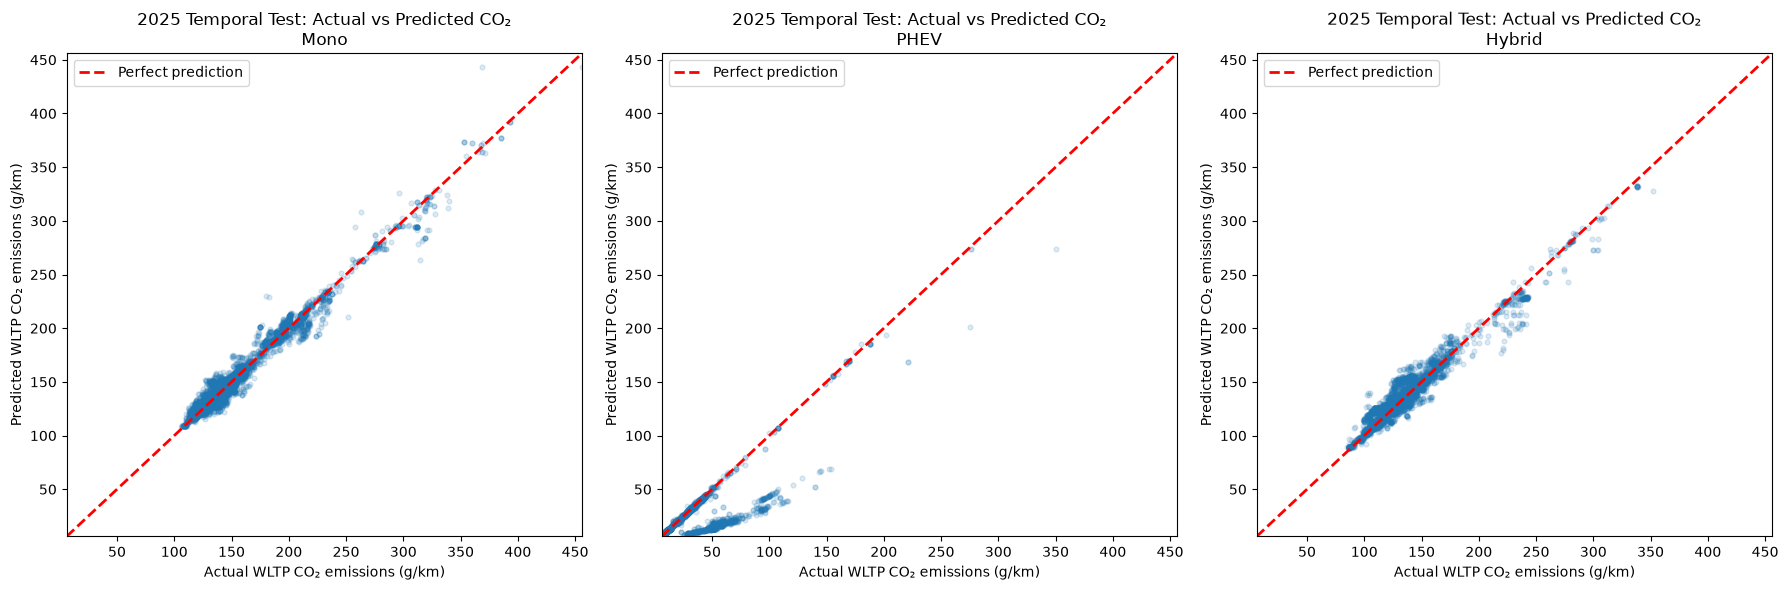

In [19]:
import matplotlib.pyplot as plt
import numpy as np


def plot_actual_vs_predicted_triplet(
    y_test_1, y_pred_1, label_1,
    y_test_2, y_pred_2, label_2,
    y_test_3, y_pred_3, label_3,
):
    plot_sample_size = 20_000

    rng = np.random.default_rng(42)

    def subsample(y_test, y_pred):
        n = len(y_test)
        size = min(plot_sample_size, n)
        positions = rng.choice(n, size=size, replace=False)
        y_test_array = y_test.to_numpy() if hasattr(y_test, "to_numpy") else np.asarray(y_test)
        y_pred_array = np.asarray(y_pred)
        return y_test_array[positions], y_pred_array[positions]

    s_actual_1, s_pred_1 = subsample(y_test_1, y_pred_1)
    s_actual_2, s_pred_2 = subsample(y_test_2, y_pred_2)
    s_actual_3, s_pred_3 = subsample(y_test_3, y_pred_3)

    lower_limit = min(
        s_actual_1.min(), s_pred_1.min(),
        s_actual_2.min(), s_pred_2.min(),
        s_actual_3.min(), s_pred_3.min(),
    )

    upper_limit = max(
        s_actual_1.max(), s_pred_1.max(),
        s_actual_2.max(), s_pred_2.max(),
        s_actual_3.max(), s_pred_3.max(),
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    def _plot_ax(ax, actual, predicted, title):
        ax.scatter(actual, predicted, alpha=0.15, s=12)
        ax.plot(
            [lower_limit, upper_limit],
            [lower_limit, upper_limit],
            color="red",
            linestyle="--",
            linewidth=2,
            label="Perfect prediction",
        )
        ax.set_xlim(lower_limit, upper_limit)
        ax.set_ylim(lower_limit, upper_limit)
        ax.set_xlabel("Actual WLTP CO₂ emissions (g/km)")
        ax.set_ylabel("Predicted WLTP CO₂ emissions (g/km)")
        ax.set_title(title)
        ax.legend()

    _plot_ax(axes[0], s_actual_1, s_pred_1, f"2025 Temporal Test: Actual vs Predicted CO₂\n{label_1}")
    _plot_ax(axes[1], s_actual_2, s_pred_2, f"2025 Temporal Test: Actual vs Predicted CO₂\n{label_2}")
    _plot_ax(axes[2], s_actual_3, s_pred_3, f"2025 Temporal Test: Actual vs Predicted CO₂\n{label_3}")

    plt.tight_layout()
    plt.show()

print("Plotting Actual vs Predicted CO₂ for the triplet of datasets")
plot_actual_vs_predicted_triplet(
    y_test_2025_Mono, y_pred_2025_mono, "Mono",
    y_test_2025_Phev, y_pred_2025_phev, "PHEV",
    y_test_2025_Hybrid, y_pred_2025_hybrid, "Hybrid"
)


The scatter plot compares the actual and predicted WLTP CO₂ emissions for the 2025 temporal test set. The red dashed line represents perfect predictions, where the predicted value is equal to the actual value.

The Mono and Hybrid models showed strong agreement between actual and predicted WLTP CO₂ emissions, with most observations concentrated close to the perfect-prediction line. Prediction errors increased slightly for high-emission vehicles, where relatively few observations were available.

The PHEV model showed a wider error distribution and a clear tendency to underpredict CO₂ emissions for some vehicles. Several observations with moderate or high actual emissions were predicted substantially below the perfect-prediction line. This result is consistent with the segment-level error analysis, which identified unseen and high-performance petrol/electric PHEV configurations as the main source of large prediction errors.

# Residual vs. Actual plot

```text
residual=actual CO2−predicted CO2
```
- Positive residual → The model underestimated CO2 levels.
- Negative residual → The model overestimated CO2 levels.

Plotting Residuals vs Actual CO₂ for the triplet of datasets


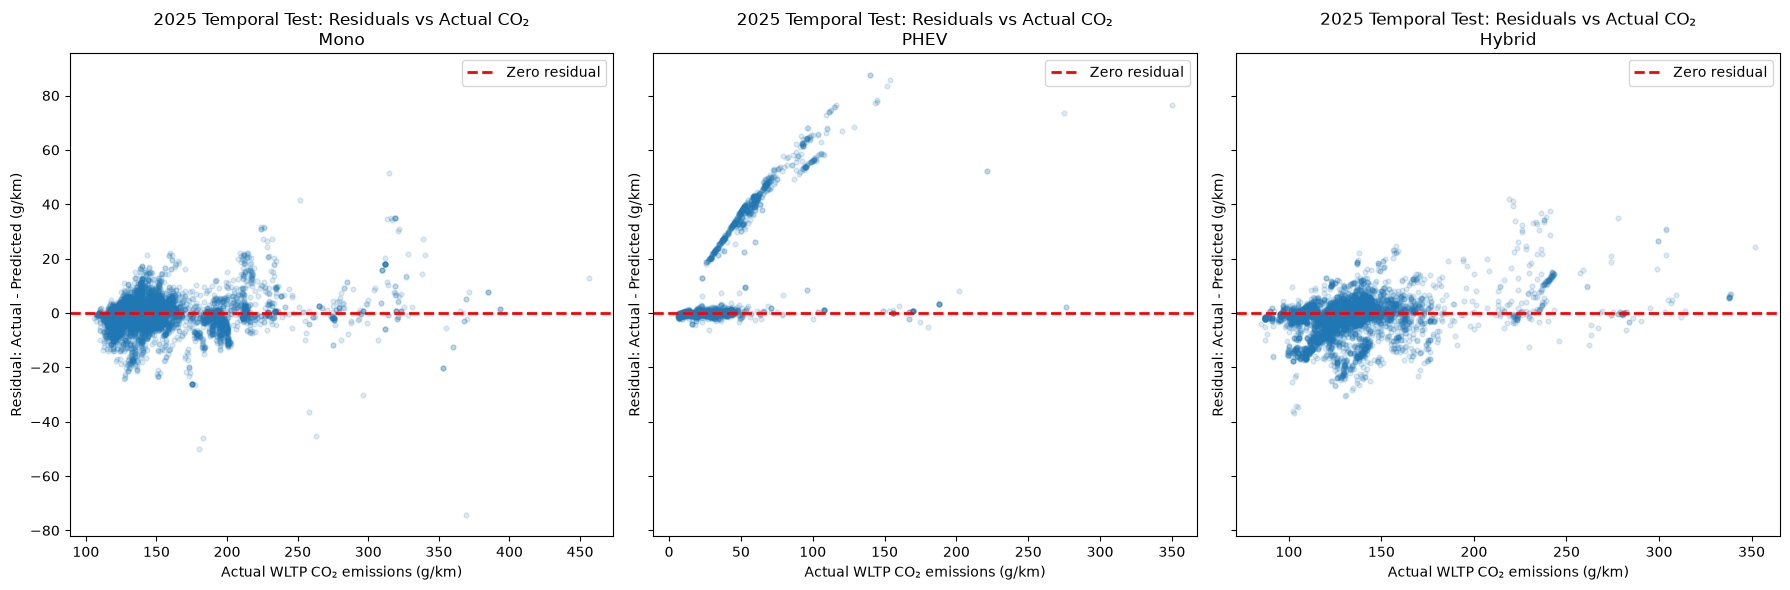

In [20]:
def plot_residuals_vs_actual_triplet(
    y_test_1, y_pred_1, label_1,
    y_test_2, y_pred_2, label_2,
    y_test_3, y_pred_3, label_3,
    plot_sample_size=20_000,
):
    rng = np.random.default_rng(42)

    def subsample_residuals(y_test, y_pred):
        y_actual = (
            y_test.to_numpy()
            if hasattr(y_test, "to_numpy")
            else np.asarray(y_test)
        )
        y_predicted = np.asarray(y_pred)

        if len(y_actual) != len(y_predicted):
            raise ValueError(
                "y_test and y_pred must have the same length."
            )

        sample_size = min(plot_sample_size, len(y_actual))

        sample_positions = rng.choice(
            len(y_actual),
            size=sample_size,
            replace=False,
        )

        residuals = y_actual - y_predicted

        return (
            y_actual[sample_positions],
            residuals[sample_positions],
        )

    actual_1, residuals_1 = subsample_residuals(y_test_1, y_pred_1)
    actual_2, residuals_2 = subsample_residuals(y_test_2, y_pred_2)
    actual_3, residuals_3 = subsample_residuals(y_test_3, y_pred_3)

    lower_y_limit = min(
        residuals_1.min(),
        residuals_2.min(),
        residuals_3.min(),
    )

    upper_y_limit = max(
        residuals_1.max(),
        residuals_2.max(),
        residuals_3.max(),
    )

    y_padding = (upper_y_limit - lower_y_limit) * 0.05

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6),
        sharey=True,
    )

    def plot_axis(ax, actual, residuals, label):
        ax.scatter(
            actual,
            residuals,
            alpha=0.15,
            s=12,
        )

        ax.axhline(
            y=0,
            color="red",
            linestyle="--",
            linewidth=2,
            label="Zero residual",
        )

        ax.set_xlabel("Actual WLTP CO₂ emissions (g/km)")
        ax.set_ylabel("Residual: Actual - Predicted (g/km)")
        ax.set_title(
            "2025 Temporal Test: Residuals vs Actual CO₂\n"
            f"{label}"
        )
        ax.set_ylim(
            lower_y_limit - y_padding,
            upper_y_limit + y_padding,
        )
        ax.legend()

    plot_axis(axes[0], actual_1, residuals_1, label_1)
    plot_axis(axes[1], actual_2, residuals_2, label_2)
    plot_axis(axes[2], actual_3, residuals_3, label_3)

    plt.tight_layout()
    plt.show()

print("Plotting Residuals vs Actual CO₂ for the triplet of datasets")
plot_residuals_vs_actual_triplet(
    y_test_2025_Mono, y_pred_2025_mono, "Mono",
    y_test_2025_Phev, y_pred_2025_phev, "PHEV",
    y_test_2025_Hybrid, y_pred_2025_hybrid, "Hybrid"
)


The residual plots show clear differences in prediction behaviour across the three vehicle segments. Mono and Hybrid residuals are generally concentrated around zero, indicating limited systematic bias for most observations. The residual spread increases at higher actual CO₂ values, suggesting that extreme-emission vehicles are more difficult to predict accurately.

The PHEV model shows a substantially wider residual distribution, with many large positive residuals. Since residuals are defined as actual minus predicted emissions, these positive values indicate systematic underprediction for a subset of PHEV vehicles. This pattern is particularly visible for vehicles with moderate to high actual CO₂ emissions and is consistent with the segment-level analysis identifying unseen and high-performance PHEV configurations as the primary source of large prediction errors.

# Error Analysis by Fuel Type and Fuel Mode:

In [21]:
def evaluate_fuel_error(y_test, y_pred_2025, X_test, fuel_prefix="Ft_"):
    """
    y_test, y_pred_2025: CO2 target and prediction (array/Series)
    X_test: scaled test features (DataFrame)
    fuel_prefix: prefix of the one-hot encoded fuel type columns (default: "Ft_")
    """
    import numpy as np
    import pandas as pd
    from IPython.display import display

    # 1) Basic error metrics
    y_actual = y_test.to_numpy() if hasattr(y_test, "to_numpy") else np.asarray(y_test)
    y_pred = np.asarray(y_pred_2025)

    evaluation = pd.DataFrame({
        "actual_co2": y_actual,
        "predicted_co2": y_pred,
        "absolute_error": np.abs(y_actual - y_pred),
        "residual": y_actual - y_pred,
    })

    # 2) Find existing Ft_* columns in X_test
    fuel_cols = [c for c in X_test.columns if c.startswith(fuel_prefix)]

    if len(fuel_cols) == 0:
        # If no fuel type column exists, mark all as "unknown"
        evaluation["fuel_type"] = "unknown"
    else:
        # For each row, take the name of the Ft_* that equals 1 as the fuel_type
        # One-hot encoding assumption: at most one column is 1 per row
        fuel_matrix = X_test[fuel_cols].to_numpy()
        idx_max = np.argmax(fuel_matrix, axis=1)  # 1 olan sütunun indeksi

       # If no column is 1 (all are 0), let's mark that row as "unknown"
        row_has_fuel = fuel_matrix.any(axis=1)

        fuel_names = [c.replace(fuel_prefix, "", 1) for c in fuel_cols]
        fuel_type = np.array([fuel_names[i] for i in idx_max])
        fuel_type[~row_has_fuel] = "unknown"

        evaluation["fuel_type"] = fuel_type

    # Summary Statistics by Fuel Type
    fuel_error_summary = (
        evaluation
        .groupby("fuel_type", dropna=False)
        .agg(
            records=("actual_co2", "size"),
            actual_mean=("actual_co2", "mean"),
            predicted_mean=("predicted_co2", "mean"),
            mean_residual=("residual", "mean"),
            mae=("absolute_error", "mean"),
            rmse=(
                "residual",
                lambda values: np.sqrt(np.mean(np.square(values))),
            ),
        )
        .sort_values("mae", ascending=False)
        .round(4)
    )

    display(fuel_error_summary)
    return fuel_error_summary

print("Error analysis by Fuel Type and Fuel Mode:")
print("Mono:")
evaluate_fuel_error(y_test_2025_Mono, final_model_mono.predict(X_test_2025_Mono_scaled[FINAL_FEATURES_MONO]), X_test_2025_Mono_scaled[FINAL_FEATURES_MONO])
print("----")

print("PHEV:")
evaluate_fuel_error(y_test_2025_Phev, final_model_phev.predict(X_test_2025_Phev_scaled[FINAL_FEATURES_PHEV]), X_test_2025_Phev_scaled[FINAL_FEATURES_PHEV])
print("----")

print("Hybrid:")
evaluate_fuel_error(y_test_2025_Hybrid, final_model_hybrid.predict(X_test_2025_Hybrid_scaled[FINAL_FEATURES_HYBRID]), X_test_2025_Hybrid_scaled[FINAL_FEATURES_HYBRID])
print("----")

Error analysis by Fuel Type and Fuel Mode:
Mono:


,records,actual_mean,predicted_mean,mean_residual,mae,rmse
fuel_type,,,,,,
diesel,3121,157.1871,157.9002,-0.7130,4.7213,6.8653
petrol,3736,147.8231,148.0224,-0.1994,3.1145,5.0324


----
PHEV:


,records,actual_mean,predicted_mean,mean_residual,mae,rmse
fuel_type,,,,,,
petrol/electric,2466,36.5780,27.3795,9.1985,9.7013,20.6618
diesel/electric,229,22.6742,13.6039,9.0703,9.3700,18.0744


----
Hybrid:


,records,actual_mean,predicted_mean,mean_residual,mae,rmse
fuel_type,,,,,,
diesel,1276,147.2904,150.9864,-3.6960,6.9474,9.8461
petrol,3907,130.6316,131.6426,-1.0110,4.2618,6.4292


----


## Analysis of the Largest Prediction Errors:

In [22]:
def analyze_top_20_errors(y_test, y_pred_2025, X_test, seen_mask):
    error_analysis_2025 = X_test.reset_index(drop=True).copy()

    error_analysis_2025["actual_co2_g_km"] = y_test.to_numpy()
    error_analysis_2025["predicted_co2_g_km"] = y_pred_2025
    error_analysis_2025["residual_g_km"] = (
        error_analysis_2025["actual_co2_g_km"]
        - error_analysis_2025["predicted_co2_g_km"]
    )
    error_analysis_2025["absolute_error_g_km"] = (
        error_analysis_2025["residual_g_km"].abs()
    )
    error_analysis_2025["configuration_status"] = np.where(
        seen_mask,
        "seen",
        "unseen",
    )

    inspection_columns = [
        "Vehicle",
        "Mk",
        "Cn",
        "Ft",
        "Fm",
        "m (kg)",
        "ec (cm3)",
        "ep (KW)",
        "Electric range (km)",
        "IT",
        "actual_co2_g_km",
        "predicted_co2_g_km",
        "residual_g_km",
        "absolute_error_g_km",
        "configuration_status",
    ]

    inspection_columns = [
        column
        for column in inspection_columns
        if column in error_analysis_2025.columns
    ]

    top_20_errors = (
        error_analysis_2025[
            inspection_columns
        ]
        .sort_values(
            "absolute_error_g_km",
            ascending=False,
        )
        .head(20)
        .round({
            "m (kg)": 1,
            "ec (cm3)": 1,
            "ep (KW)": 1,
            "Electric range (km)": 1,
            "actual_co2_g_km": 2,
            "predicted_co2_g_km": 2,
            "residual_g_km": 2,
            "absolute_error_g_km": 2,
        })
    )

    display(top_20_errors)

print("Top 20 errors for Mono:")
analyze_top_20_errors(y_test_2025_Mono, y_pred_2025_mono, X_test_2025_Mono_scaled[FINAL_FEATURES_MONO], seen_mask_mono)
print("----")

print("Top 20 errors for PHEV:")
analyze_top_20_errors(y_test_2025_Phev, y_pred_2025_phev, X_test_2025_Phev_scaled[FINAL_FEATURES_PHEV], seen_mask_phev)
print("----")

print("Top 20 errors for Hybrid:")
analyze_top_20_errors(y_test_2025_Hybrid, y_pred_2025_hybrid, X_test_2025_Hybrid_scaled[FINAL_FEATURES_HYBRID], seen_mask_hybrid)
print("----")

Top 20 errors for Mono:


,ec (cm3),ep (KW),actual_co2_g_km,predicted_co2_g_km,residual_g_km,absolute_error_g_km,configuration_status
2693,3.9214,4.8993,369.0000,443.1600,-74.1600,74.1600,seen
2052,3.1085,5.4120,315.0000,263.4400,51.5600,51.5600,unseen
2765,2.1534,1.9942,180.0000,230.2100,-50.2100,50.2100,unseen
2764,2.1534,1.9942,183.0000,229.1600,-46.1600,46.1600,unseen
2499,4.6122,4.2779,263.0000,308.3700,-45.3700,45.3700,unseen
2712,0.5225,0.9223,252.0000,210.3000,41.7000,41.7000,unseen
1317,4.6122,5.3654,258.0000,294.3800,-36.3800,36.3800,unseen
2550,3.9214,5.2101,319.0000,284.0700,34.9300,34.9300,unseen
2551,3.9214,5.2101,319.0000,284.0700,34.9300,34.9300,unseen
2549,3.9214,5.2101,319.0000,284.0700,34.9300,34.9300,unseen


----
Top 20 errors for PHEV:


,ec (cm3),ep (KW),Electric range (km),actual_co2_g_km,predicted_co2_g_km,residual_g_km,absolute_error_g_km,configuration_status
1215,3.2791,3.8035,-0.4162,140.0000,52.5600,87.4400,87.4400,unseen
1216,3.2791,3.8035,-0.4162,140.0000,52.5600,87.4400,87.4400,unseen
1227,-0.0604,-0.0894,-1.1848,154.0000,68.4100,85.5900,85.5900,seen
1229,-0.0604,-0.0894,-1.1499,152.0000,68.5800,83.4200,83.4200,seen
1228,-0.0604,-0.0894,-1.1149,145.0600,66.6100,78.4500,78.4500,seen
1230,-0.0604,-0.0894,-1.1149,144.5000,66.7700,77.7300,77.7300,seen
1226,-0.0604,-0.0894,-1.0950,143.2900,65.9400,77.3500,77.3500,seen
2344,3.2791,3.6029,-0.1454,116.0000,39.4900,76.5100,76.5100,seen
1212,7.4589,5.8236,-2.2678,350.0000,273.6500,76.3500,76.3500,unseen
2348,3.2791,3.6029,-0.1437,115.2000,39.5100,75.6900,75.6900,seen


----
Top 20 errors for Hybrid:


,ec (cm3),ep (KW),Electric range (km),actual_co2_g_km,predicted_co2_g_km,residual_g_km,absolute_error_g_km,configuration_status
1974,1.7945,0.7216,0.0000,219.0000,177.0500,41.9500,41.9500,seen
1956,1.7945,0.2024,0.0000,221.0000,179.7400,41.2600,41.2600,seen
1955,1.7945,0.2024,0.0000,221.0000,181.5200,39.4800,39.4800,seen
2463,0.2011,2.5535,0.0000,241.0000,203.6500,37.3500,37.3500,unseen
2467,0.2011,2.5535,0.0000,236.0000,199.0500,36.9500,36.9500,unseen
3395,-0.5798,-0.2447,0.0000,102.9600,139.9100,-36.9500,36.9500,unseen
3394,-0.5798,-0.2447,0.0000,102.0400,138.0800,-36.0400,36.0400,unseen
2462,0.2011,2.5535,0.0000,239.0000,203.7600,35.2400,35.2400,unseen
2992,1.7961,2.8419,0.0000,278.0000,243.2000,34.8000,34.8000,unseen
3392,-0.5798,-0.2447,0.0000,104.9700,139.5400,-34.5600,34.5600,unseen


----


The 20 records with the largest absolute errors were examined separately for the Mono, PHEV, and Hybrid models to identify systematic prediction limitations. The error patterns differed substantially between the three vehicle segments.

The largest error in the Mono segment was **74.16 g/km** for a seen configuration with an actual CO₂ value of **369.0 g/km** and a prediction of **443.16 g/km**. This was an overprediction, as indicated by the negative residual of **−74.16 g/km**. Other large Mono errors occurred for high-emission vehicles, with both underprediction and overprediction observed. Most of these cases involved unseen configurations, suggesting that prediction accuracy declines when technical combinations are not well represented in the training data.

The PHEV segment produced the largest overall errors. The highest PHEV error was **87.44 g/km** for an unseen configuration with actual emissions of **140.0 g/km** and a prediction of **52.56 g/km**. This represents substantial underprediction. The next-largest PHEV errors also predominantly had positive residuals, indicating that the model systematically underestimated emissions for several high-error PHEV configurations. Although many of these records were classified as seen core configurations, their large errors show that matching engine capacity, engine power, and electric range alone does not guarantee that the full vehicle configuration is sufficiently represented.

The Hybrid model had smaller maximum errors than the PHEV model, with the largest absolute error equal to **41.95 g/km**. This case was a seen configuration with actual emissions of **219.0 g/km** and a prediction of **177.05 g/km**, resulting in underprediction. Most large Hybrid errors were associated with unseen configurations and involved moderate-to-high actual CO₂ values. Both underprediction and overprediction occurred, although underprediction was more common among the highest-error records.

Overall, the largest prediction errors were concentrated in technically unusual or insufficiently represented vehicle configurations. The PHEV model showed the strongest systematic underprediction, while the Mono and Hybrid models showed more balanced errors but reduced accuracy for rare or high-emission vehicle configurations.

# Distribution of Absolute Prediction Errors

Overall regression metrics such as MAE and RMSE summarise model performance with a single value, but they do not show how errors are distributed across individual records.

To better understand the practical accuracy of the final model, the distribution of absolute prediction errors was analysed on the held-out 2025 temporal test set.

This analysis includes:

- A histogram of absolute errors, showing how frequently different error magnitudes occur.
- Error percentiles, showing the prediction error threshold below which a given proportion of records falls.

Unlike signed residuals, absolute errors do not distinguish between overprediction and underprediction. Instead, they measure the magnitude of the prediction error in g/km.

This analysis helps distinguish the typical prediction quality for the majority of vehicles from the relatively small number of rare, high-error vehicle configurations that disproportionately affect RMSE.

Plotting Distribution of Absolute Errors for the triplet of datasets


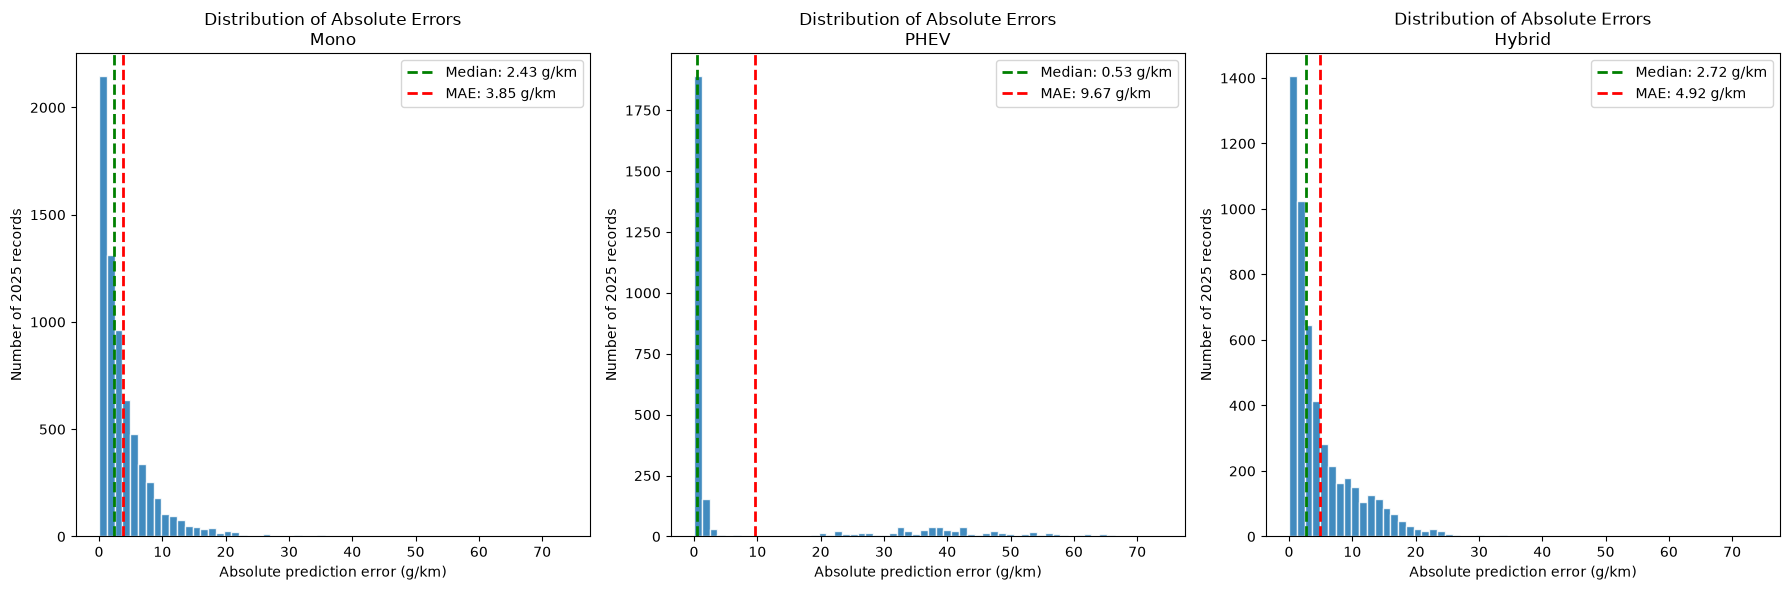

,Model,Metric,Value,Unit
0,Mono,50th percentile (Median),2.4300,g/km
1,Mono,75th percentile,5.1300,g/km
2,Mono,90th percentile,8.9400,g/km
3,Mono,95th percentile,12.4400,g/km
4,Mono,99th percentile,20.8900,g/km
5,Mono,Maximum,74.1600,g/km
6,Mono,Error ≤ 5 g/km,74.2700,%
7,Mono,Error ≤ 10 g/km,92.2100,%
8,Mono,Error ≤ 20 g/km,98.7200,%
9,PHEV,50th percentile (Median),0.5300,g/km


In [23]:
def plot_absolute_error_distribution_triplet(
    y_test_1, y_pred_1, label_1,
    y_test_2, y_pred_2, label_2,
    y_test_3, y_pred_3, label_3,
    bins=60,
):
    def get_absolute_errors(y_test, y_pred):
        y_actual = (
            y_test.to_numpy()
            if hasattr(y_test, "to_numpy")
            else np.asarray(y_test)
        )

        y_predicted = np.asarray(y_pred)

        if len(y_actual) != len(y_predicted):
            raise ValueError(
                "y_test and y_pred must have the same length."
            )

        return np.abs(y_actual - y_predicted)

    def create_error_summary(absolute_errors, label):
        return pd.DataFrame({
            "Model": [label] * 9,
            "Metric": [
                "50th percentile (Median)",
                "75th percentile",
                "90th percentile",
                "95th percentile",
                "99th percentile",
                "Maximum",
                "Error ≤ 5 g/km",
                "Error ≤ 10 g/km",
                "Error ≤ 20 g/km",
            ],
            "Value": [
                np.percentile(absolute_errors, 50),
                np.percentile(absolute_errors, 75),
                np.percentile(absolute_errors, 90),
                np.percentile(absolute_errors, 95),
                np.percentile(absolute_errors, 99),
                absolute_errors.max(),
                (absolute_errors <= 5).mean() * 100,
                (absolute_errors <= 10).mean() * 100,
                (absolute_errors <= 20).mean() * 100,
            ],
            "Unit": [
                "g/km",
                "g/km",
                "g/km",
                "g/km",
                "g/km",
                "g/km",
                "%",
                "%",
                "%",
            ],
        })

    absolute_errors_1 = get_absolute_errors(y_test_1, y_pred_1)
    absolute_errors_2 = get_absolute_errors(y_test_2, y_pred_2)
    absolute_errors_3 = get_absolute_errors(y_test_3, y_pred_3)

    error_summary = pd.concat(
        [
            create_error_summary(absolute_errors_1, label_1),
            create_error_summary(absolute_errors_2, label_2),
            create_error_summary(absolute_errors_3, label_3),
        ],
        ignore_index=True,
    )

    plot_upper_limit = max(
        np.percentile(absolute_errors_1, 99.5),
        np.percentile(absolute_errors_2, 99.5),
        np.percentile(absolute_errors_3, 99.5),
    )

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6),
        sharex=True,
    )

    def plot_axis(ax, absolute_errors, label):
        median_error = np.median(absolute_errors)
        mae = np.mean(absolute_errors)

        ax.hist(
            absolute_errors,
            bins=bins,
            range=(0, plot_upper_limit),
            edgecolor="white",
            alpha=0.85,
        )

        ax.axvline(
            median_error,
            color="green",
            linestyle="--",
            linewidth=2,
            label=f"Median: {median_error:.2f} g/km",
        )

        ax.axvline(
            mae,
            color="red",
            linestyle="--",
            linewidth=2,
            label=f"MAE: {mae:.2f} g/km",
        )

        ax.set_xlabel("Absolute prediction error (g/km)")
        ax.set_ylabel("Number of 2025 records")
        ax.set_title(
            "Distribution of Absolute Errors\n"
            f"{label}"
        )
        ax.legend()

    plot_axis(axes[0], absolute_errors_1, label_1)
    plot_axis(axes[1], absolute_errors_2, label_2)
    plot_axis(axes[2], absolute_errors_3, label_3)

    plt.tight_layout()
    plt.show();
    display(error_summary.round(2))

print("Plotting Distribution of Absolute Errors for the triplet of datasets")
plot_absolute_error_distribution_triplet(
    y_test_2025_Mono, y_pred_2025_mono, "Mono",
    y_test_2025_Phev, y_pred_2025_phev, "PHEV",
    y_test_2025_Hybrid, y_pred_2025_hybrid, "Hybrid"
)